# Infer transmission and recovery from three SIR maps

The presentation shows us which people are infectious on a 24 × 24 grid
at steps 4, 8, and 12. We want a range of plausible values for two
probabilities, **transmission** $p$ and **recovery** $q$. We know the true
values here because we made the example. The inference model only receives
the summaries, and we use the truth afterward to check its answer.

We'll simulate many other outbreaks, train a **neural posterior estimator
(NPE)**, then compare what it learns from counts alone with what it learns
when we tell it who was still infectious at the next visit.

In [1]:
from copy import deepcopy
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import torch

from sir import (
    OBSERVED_SEED, OBSERVED_THETA, SUMMARY_NAMES, VISITS,
    simulate_visits, simulate_summaries, summarize,
)

# Reuse the same flow implementation as the line-regression notebook.
sys.path.insert(0, str(Path("../line-regressor").resolve()))
from flow import ConditionalFlow

torch.set_num_threads(2)
results = Path("results")
results.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

COLORS = {"counts": "#69798d", "counts_overlap": "#176c61"}
LABELS = {"counts": "Counts only", "counts_overlap": "Counts + overlaps"}


def show_and_save(fig, name):
    fig.savefig(results / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


## 1. Make the three observed maps

Each cell is one person. Four people in the center start infectious. For
a susceptible person with $k$ infectious neighbors, escaping infection
means that all $k$ contacts fail. Their chance of becoming infectious is
therefore $1-(1-p)^k$. Neighbors share a side. The borders of the grid do
not wrap around. An infectious person recovers with probability $q$ each
step and stays recovered. Compute both changes from the old grid before
writing the next grid.

The code in [sir.py](sir.py) follows those rules. The seed and parameters
below reproduce the maps in the presentation. A red cell is infectious.
The pale cells include susceptible and recovered people.

Observed maps: (1, 3, 24, 24) → (datasets, visits, rows, columns)
Observed summaries: {'C4': 33, 'C8': 60, 'C12': 86, 'O4,8': 17, 'O8,12': 25}


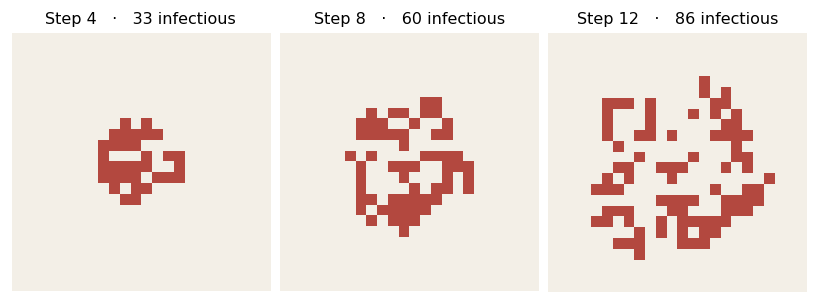

In [2]:
observed_maps = simulate_visits(OBSERVED_THETA, np.random.default_rng(OBSERVED_SEED))
observed = summarize(observed_maps)[0]
np.testing.assert_array_equal(observed, [33, 60, 86, 17, 25])

print("Observed maps:", observed_maps.shape, "→ (datasets, visits, rows, columns)")
print("Observed summaries:", dict(zip(SUMMARY_NAMES, observed.tolist())))

fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.65), layout="constrained")
for visit, mask, count, ax in zip(VISITS, observed_maps[0], observed[:3], axes):
    ax.imshow(mask, cmap=ListedColormap(["#f3efe7", "#b3483f"]), vmin=0, vmax=1)
    ax.set_title(f"Step {visit}   ·   {count} infectious", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
show_and_save(fig, "observed_maps")

## 2. Turn the maps into five numbers

Let $Y_t(v)$ be 1 if person $v$ is red at visit $t$, and 0 otherwise.
The **count** $C_t=\sum_v Y_t(v)$ tells us how many people are infectious.
The **overlap** $O_{t,t+4}=\sum_v Y_t(v)Y_{t+4}(v)$ counts the people
who are red at both visits. The two rows of the comparison use

$$
s_{\text{counts}}=(C_4,C_8,C_{12}),\qquad
s_{\text{full}}=(C_4,C_8,C_{12},O_{4,8},O_{8,12}).
$$

Because there is no reinfection, someone who was infectious at $t$ is
still infectious at $t+4$ with probability $(1-q)^4$. Given the grid at
$t$, each of the $C_t$ people has that same chance independently, so
$O_{t,t+4}\mid Y_t\sim\operatorname{Binomial}(C_t,(1-q)^4)$ under this
model. Counts also depend on $q$, but mix the people who stayed
infectious with people who got infected in the meantime.

A rough estimate comes from solving $(1-\widehat q)^4=(17+25)/(33+60)$.
The posterior below accounts for uncertainty and uses all five numbers
jointly. We are estimating $p(\theta\mid s_{\text{full}})$, the posterior
given the summaries. It may differ from the posterior given all 1,728
indicators, since the summaries discard the spatial arrangement.

In [3]:
retention = observed[3:].sum() / observed[:2].sum()
print(f"Pooled infectious retention: {retention:.3f}")
print(f"Recovery estimate from retention: {1 - retention**0.25:.3f}")

Pooled infectious retention: 0.452
Recovery estimate from retention: 0.180


## 3. Generate examples for the neural network

Our prior draws $p$ and $q$ independently and uniformly between zero and
one. For each draw we simulate the three visits and compute the same five
numbers. The training, validation, and test sets contain separate
simulations. Validation chooses when to stop training. The test set
measures accuracy after training. Neither model trains on the observed maps.

Counts are often small and sometimes zero. We apply $\log(1+s)$ to keep
the zeros and make large counts less extreme. Each model then subtracts
the mean and divides by the standard deviation of each transformed
summary, computed from the training rows alone.

In [4]:
num_train, num_valid, num_test = 36_000, 4_000, 4_000
rng = np.random.default_rng(302)
parameters = rng.random((num_train + num_valid + num_test, 2))
raw_summaries = simulate_summaries(parameters, rng)

# This uniform prior has no point mass at either endpoint.
theta = torch.tensor(parameters, dtype=torch.float32)
context = torch.from_numpy(np.log1p(raw_summaries).astype(np.float32))
train = slice(0, num_train)
valid = slice(num_train, num_train + num_valid)
test = slice(num_train + num_valid, None)

print("Parameter tensor:", tuple(theta.shape), "→ one row [p, q] per outbreak")
print("Summary tensor:  ", tuple(context.shape), "→ five numbers per outbreak")
print("Training / validation / test:", num_train, num_valid, num_test)

Parameter tensor: (44000, 2) → one row [p, q] per outbreak
Summary tensor:   (44000, 5) → five numbers per outbreak
Training / validation / test: 36000 4000 4000


## 4. Train a conditional normalizing flow

**NPE** learns the density of the two parameters given the summaries,
$q_\phi(\theta\mid s)$, from the simulated pairs. In this notation
$q_\phi$ is a density. The scalar $q$ is our recovery probability.

A **normalizing flow** starts with two independent standard normal
draws. An invertible transformation changes them into a draw of $(p,q)$.
In each coupling layer, a small network uses one coordinate and the
summaries to scale and shift the other coordinate. Alternating layers
allow both coordinates to change. A final sigmoid maps each number to
$(0,1)$ to match the prior bounds. To evaluate density, the flow reverses
the transformations and uses their Jacobians to correct for stretching.

The loss is the mean negative log density of the true parameters
$-\frac{1}{N}\sum_i\log q_\phi(\theta_i\mid s_i)$. In expectation this
minimizes the average KL divergence from the simulator's posterior
to our approximation, up to a constant in the loss. The training below
evaluates the **flow's** density, which has a formula.

We use NPE because the output is a two-dimensional posterior that we
want to sample directly. The flow can represent dependence between
$p$ and $q$. The input is only three or five numbers. A separate neural
likelihood and sampling algorithm would add work for this example.

In [5]:
def train_flow(training_context, validation_context):
    # Fit one flow and restore its best validation weights.
    torch.manual_seed(407)
    flow = ConditionalFlow(
        observation_size=training_context.shape[1],
        lower=(0.0, 0.0),
        upper=(1.0, 1.0),
        num_layers=6,
        hidden_size=64,
    )
    flow.fit_observation_standardization(training_context)
    optimizer = torch.optim.Adam(flow.parameters(), lr=0.001)
    history = {"train": [], "validation": []}
    best_loss = float("inf")
    best_weights = None
    patience = 10
    batch_size = 512

    for epoch in range(1, 71):
        flow.train()
        total_loss = 0.0
        for batch in torch.randperm(num_train).split(batch_size):
            log_density = flow.log_prob(theta[train][batch], training_context[batch])
            loss = -log_density.mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)

        flow.eval()
        with torch.no_grad():
            validation_loss = -flow.log_prob(theta[valid], validation_context).mean().item()
        if not np.isfinite(validation_loss):
            raise RuntimeError("Training produced a non-finite validation loss.")
        history["train"].append(total_loss / num_train)
        history["validation"].append(validation_loss)

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_epoch = epoch
            best_weights = deepcopy(flow.state_dict())
        if epoch == 1 or epoch % 10 == 0:
            print(f"  Epoch {epoch:2d}  validation loss = {validation_loss:.3f}", flush=True)
        if epoch - best_epoch >= patience:
            break

    flow.load_state_dict(best_weights)
    history["best_epoch"] = best_epoch
    print(f"  Restored epoch {best_epoch} (ran {epoch} epochs).", flush=True)
    return flow, history


flows, histories = {}, {}
inputs = {"counts": slice(0, 3), "counts_overlap": slice(0, 5)}
for name, columns in inputs.items():
    print(LABELS[name], flush=True)
    flows[name], histories[name] = train_flow(context[train, columns], context[valid, columns])
    torch.save(flows[name].state_dict(), results / f"{name}_flow.pt")

Counts only


  Epoch  1  validation loss = -1.035


  Epoch 10  validation loss = -2.097


  Epoch 20  validation loss = -2.152


  Epoch 30  validation loss = -2.196


  Epoch 40  validation loss = -2.229


... (7 outputs left out)

  Epoch 30  validation loss = -2.896


  Epoch 40  validation loss = -2.968


  Epoch 50  validation loss = -2.912


  Restored epoch 40 (ran 50 epochs).


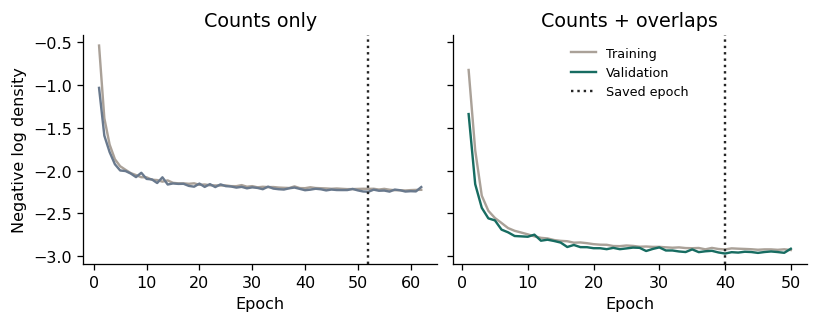

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7), layout="constrained", sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    epochs = np.arange(1, len(history["train"]) + 1)
    ax.plot(epochs, history["train"], color="#aaa198", label="Training")
    ax.plot(epochs, history["validation"], color=COLORS[name], label="Validation")
    ax.axvline(history["best_epoch"], ls=":", color="#252525", label="Saved epoch")
    ax.set(xlabel="Epoch", title=LABELS[name])
axes[0].set_ylabel("Negative log density")
axes[1].legend(frameon=False, fontsize=8)
show_and_save(fig, "training")

## 5. Check both models on unseen simulations

For each test outbreak, we know which parameters generated it. We score
each flow on the log density it assigns to that pair of true parameter
values. **Higher mean log density is better.** The prior is uniform on
the unit square, so its log density is 0. Both flows are scored on the
same outbreaks, which lets us compute a paired difference. A continuous
density can exceed 1, so log density can be positive.

We also check marginal 90% intervals for the first 1,000 test outbreaks.
If the posterior were calibrated, about 90% of the true $p$ values and
90% of the true $q$ values would fall within their respective intervals,
averaged across these prior simulations. The two checks measure different
things. Log density scores the entire joint distribution at the truth.
Coverage checks the widths and locations of the reported intervals.

In [7]:
@torch.no_grad()
def test_intervals(flow, test_context, draws=512):
    # Return 5% and 95% sample quantiles for each test outbreak.
    intervals = []
    # Repeat each context so it has its own set of Gaussian draws.
    for batch in test_context.split(32):
        gaussian = torch.randn(len(batch) * draws, 2)
        repeated_context = batch.repeat_interleave(draws, dim=0)
        posterior, _ = flow.to_parameters(gaussian, repeated_context)
        posterior = posterior.reshape(len(batch), draws, 2)
        intervals.append(torch.quantile(posterior, torch.tensor([0.05, 0.95]), dim=1))
    return torch.cat(intervals, dim=1)


metrics = {
    "dataset_sizes": {"train": num_train, "validation": num_valid, "test": num_test},
    "observed_parameters": list(OBSERVED_THETA),
    "observed_summaries": observed.tolist(),
    "coverage_cases": 1000,
    "models": {},
}
scores = {}
torch.manual_seed(511)
for name, columns in inputs.items():
    flow = flows[name]
    with torch.no_grad():
        scores[name] = flow.log_prob(theta[test], context[test, columns])
    assert torch.isfinite(scores[name]).all()

    true_values = theta[test][:1000]
    test_low, test_high = test_intervals(flow, context[test, columns][:1000])
    coverage = ((test_low <= true_values) & (true_values <= test_high)).float().mean(0)
    metric = {
        "mean_test_log_density": scores[name].mean().item(),
        "marginal_90_coverage": coverage.tolist(),
        "best_epoch": histories[name]["best_epoch"],
        "epochs_run": len(histories[name]["validation"]),
    }
    metrics["models"][name] = metric
    print(f"{LABELS[name]:18}   mean log density = {scores[name].mean():.3f}"
          f"   coverage p = {coverage[0]:.1%}, q = {coverage[1]:.1%}")

gain = scores["counts_overlap"] - scores["counts"]
gain_se = gain.std().item() / np.sqrt(len(gain))
metrics["paired_log_density_gain"] = gain.mean().item()
metrics["paired_log_density_gain_mcse"] = gain_se
print(f"Paired gain: {gain.mean():.3f} nats per outbreak (Monte Carlo SE {gain_se:.3f})")

Counts only          mean log density = 2.209   coverage p = 88.7%, q = 90.8%


Counts + overlaps    mean log density = 2.911   coverage p = 90.0%, q = 89.9%
Paired gain: 0.702 nats per outbreak (Monte Carlo SE 0.016)


## 6. Infer parameters for the presentation's maps

Give each trained flow the appropriate summaries from the observed maps.
Draw 8,000 posterior pairs from each model. An interval below runs from
the 5th to the 95th percentile for one parameter. The scatter plots
show how the two parameters vary together. The cross marks the values
we used to generate this teaching example.

Counts only
  p: mean 0.874, central 90% interval [0.637, 0.992]
  q: mean 0.489, central 90% interval [0.374, 0.556]
Counts + overlaps
  p: mean 0.422, central 90% interval [0.366, 0.483]
  q: mean 0.181, central 90% interval [0.146, 0.224]


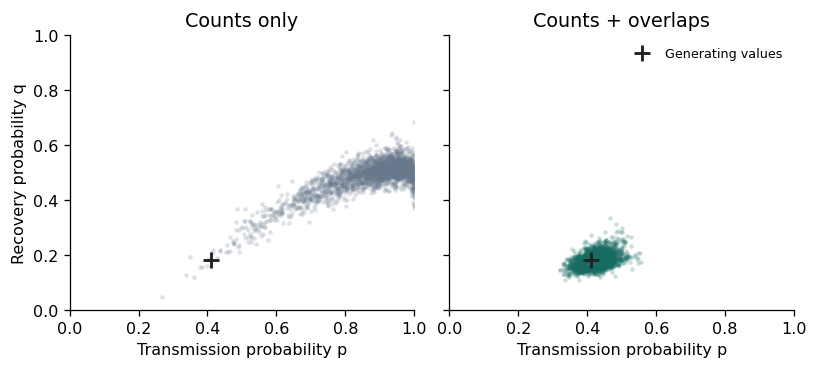

In [8]:
torch.manual_seed(601)
observed_context = torch.from_numpy(np.log1p(observed).astype(np.float32))
posterior_draws = {}
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), layout="constrained", sharey=True)
for ax, (name, columns) in zip(axes, inputs.items()):
    draws = flows[name].sample(8_000, observed_context[columns]).numpy()
    assert np.isfinite(draws).all() and ((0 <= draws) & (draws <= 1)).all()
    posterior_draws[name] = draws
    means = draws.mean(axis=0)
    intervals = np.quantile(draws, [0.05, 0.95], axis=0).T
    metrics["models"][name]["posterior_mean"] = means.tolist()
    metrics["models"][name]["posterior_marginal_90_interval"] = intervals.tolist()

    print(LABELS[name])
    for parameter, mean, (low, high) in zip(("p", "q"), means, intervals):
        print(f"  {parameter}: mean {mean:.3f}, central 90% interval [{low:.3f}, {high:.3f}]")
    ax.scatter(draws[:2500, 0], draws[:2500, 1], s=8, alpha=0.22, linewidths=0,
               color=COLORS[name], rasterized=True)
    ax.scatter(*OBSERVED_THETA, marker="+", color="#222222", s=95, linewidths=1.8,
               label="Generating values")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Transmission probability p", title=LABELS[name])
axes[0].set_ylabel("Recovery probability q")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
show_and_save(fig, "posterior")

## 7. Simulate again from the posterior

To check what the posterior predicts, draw $(p,q)$ from each fitted
flow, then simulate an independent outbreak at those values. Compare
the simulated summaries with the observed ones. A case where the
observed summary lies in the predictive interval is compatible with
the model in that respect. The same observation informed the posterior,
so this check complements the independent test-set evaluation.

The count and overlap models condition on different information.
Look at how the overlap predictions shift once the flow sees the observed overlaps. Neither model
receives information about the spatial arrangement of infections.

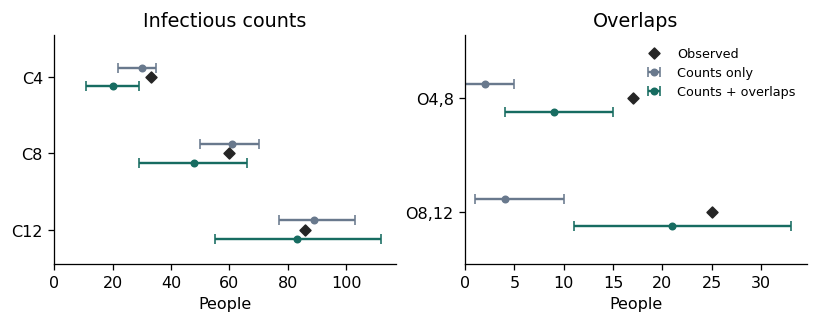

Saved the fitted weights, metrics, and figures to results/.


In [9]:
prediction_rng = np.random.default_rng(711)
for name, draws in posterior_draws.items():
    simulated = simulate_summaries(draws[:1500], prediction_rng)
    quantiles = np.quantile(simulated, [0.05, 0.5, 0.95], axis=0)
    metrics["models"][name]["predictive_05_50_95"] = quantiles.tolist()

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7), layout="constrained")
for ax, indices, title in zip(axes, [[0, 1, 2], [3, 4]], ["Infectious counts", "Overlaps"]):
    positions = np.arange(len(indices))
    ax.set_title(title)
    ax.set_xlabel("People")
    for offset, name in zip([-0.12, 0.12], posterior_draws):
        quantiles = np.array(metrics["models"][name]["predictive_05_50_95"])
        low, median, high = quantiles[:, indices]
        ax.errorbar(median, positions + offset, xerr=[median - low, high - median],
                    fmt="o", ms=4, capsize=3, color=COLORS[name], label=LABELS[name])
    ax.scatter(observed[indices], positions, marker="D", s=23, color="#252525",
               zorder=5, label="Observed")
    ax.set_yticks(positions, [SUMMARY_NAMES[i] for i in indices])
    ax.set_ylim(len(indices) - 0.55, -0.55)
    ax.set_xlim(left=0)
# The two panels use different y-axis labels.
axes[1].legend(frameon=False, fontsize=8)
show_and_save(fig, "predictive")

(results / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print("Saved the fitted weights, metrics, and figures to results/.")

### What happened in this run?

With overlaps, the posterior means were about **0.422 for transmission**
and **0.181 for recovery**, close to the generating values (0.41, 0.18).
The counts-only flow put its mass around a much faster-moving outbreak:
higher transmission replenished the infectious population while higher
recovery removed people quickly. It could reproduce the counts reasonably
well but predicted far too few of the same people still infectious at the
next visit.

The flow with overlaps assigned higher density to the true parameters on
the held-out test set. For this particular observation, the first count
(33) and the first overlap (17) still land above their central 90%
predictive intervals. Redrawing parameters and running new outbreaks
usually gives smaller values for those two summaries. This is a check
of the fitted model against one simulated outbreak. The independent
test-set scores above tell us how the two fits did across many outbreaks.

## References

- Papamakarios and Murray (2016) introduced an early neural posterior
  estimation method. [NeurIPS paper](https://proceedings.neurips.cc/paper/2016/hash/6aca97005c68f1206823815f66102863-Abstract.html)
- Dinh, Sohl-Dickstein, and Bengio (2017) describe affine couplings in
  Real NVP. [Paper](https://arxiv.org/abs/1605.08803)
- Wang and Onnela (2024) use learned summaries and ABC on a partially
  observed network SIR model. Section 4 is the closest example to these
  maps. [Paper](https://doi.org/10.1093/comnet/cnae017)

The [report](report.pdf) explains the derivations and interprets this run.